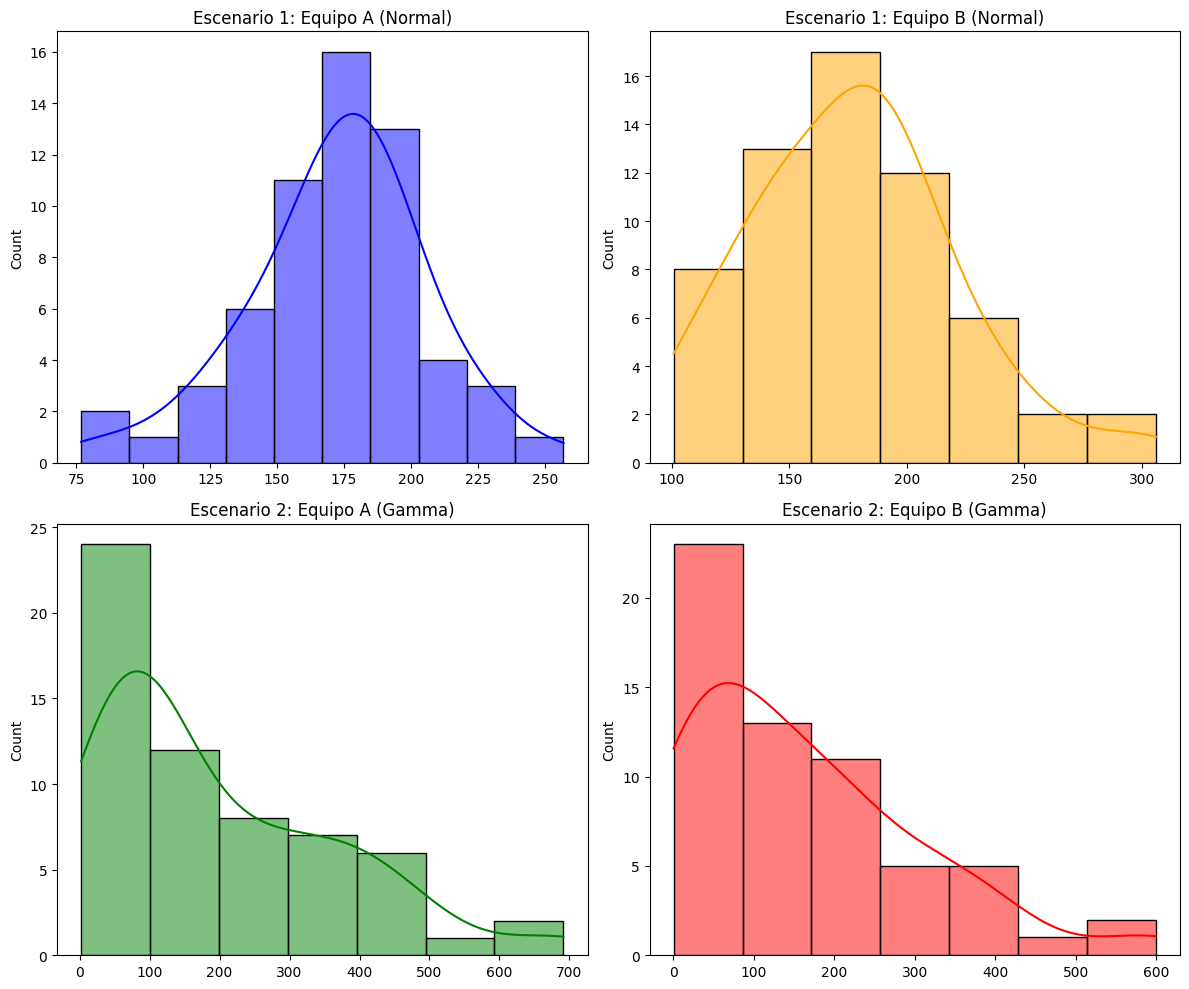

--- ESTADÍSTICAS DESCRIPTIVAS ---
Norm A: Media=172.80, Desv=33.65
Norm B: Media=177.50, Desv=43.77
Gamma A: Media=195.45, Desv=169.76
Gamma B: Media=160.70, Desv=143.41

--- a) PRUEBAS DE BONDAD DE AJUSTE (Shapiro-Wilk para Normalidad) ---
Norm A - p-value: 0.6308
Norm B - p-value: 0.1893
Gamma A - p-value: 0.0000 (Se espera que rechace normalidad)
Gamma B - p-value: 0.0001 (Se espera que rechace normalidad)

--- b) PRUEBA T-STUDENT (Paramétrica) ---
Escenario 1 (Normal) -> t-stat: -0.6591, p-value: 0.5112
Escenario 2 (Gamma)  -> t-stat: 1.2114, p-value: 0.2282

--- c) PRUEBA MANN-WHITNEY (No paramétrica) ---
Escenario 1 (Normal) -> U-stat: 1732.0000, p-value: 0.7231
Escenario 2 (Gamma)  -> U-stat: 2003.0000, p-value: 0.2879


In [ ]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Fijar semilla para que los datos aleatorios siempre sean los mismos (reproducibilidad)
np.random.seed(2026)
n = 60

# --- GENERACIÓN DE DATOS ---
# Escenario 1: Normal
A_norm = np.random.normal(loc=175, scale=30, size=n)
B_norm = np.random.normal(loc=170, scale=50, size=n)

# Escenario 2: Gamma (en Python, scale = beta)
A_gam = np.random.gamma(shape=1.2, scale=150, size=n)
B_gam = np.random.gamma(shape=0.95, scale=190, size=n)

# --- a) Histogramas y Descriptivas ---
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

sns.histplot(A_norm, kde=True, ax=axs[0,0], color='blue').set_title('Escenario 1: Equipo A (Normal)')
sns.histplot(B_norm, kde=True, ax=axs[0,1], color='orange').set_title('Escenario 1: Equipo B (Normal)')
sns.histplot(A_gam, kde=True, ax=axs[1,0], color='green').set_title('Escenario 2: Equipo A (Gamma)')
sns.histplot(B_gam, kde=True, ax=axs[1,1], color='red').set_title('Escenario 2: Equipo B (Gamma)')
plt.tight_layout()
plt.show()

print("--- ESTADÍSTICAS DESCRIPTIVAS ---")
print(f"Norm A: Media={np.mean(A_norm):.2f}, Desv={np.std(A_norm, ddof=1):.2f}")
print(f"Norm B: Media={np.mean(B_norm):.2f}, Desv={np.std(B_norm, ddof=1):.2f}")
print(f"Gamma A: Media={np.mean(A_gam):.2f}, Desv={np.std(A_gam, ddof=1):.2f}")
print(f"Gamma B: Media={np.mean(B_gam):.2f}, Desv={np.std(B_gam, ddof=1):.2f}\n")

print("--- a) PRUEBAS DE BONDAD DE AJUSTE (Shapiro-Wilk para Normalidad) ---")
# H0: Los datos son normales. Si p-value > 0.05, cumple normalidad.
print(f"Norm A - p-value: {stats.shapiro(A_norm).pvalue:.4f}")
print(f"Norm B - p-value: {stats.shapiro(B_norm).pvalue:.4f}")
print(f"Gamma A - p-value: {stats.shapiro(A_gam).pvalue:.4f} (Se espera que rechace normalidad)")
print(f"Gamma B - p-value: {stats.shapiro(B_gam).pvalue:.4f} (Se espera que rechace normalidad)\n")

# --- b) PRUEBAS DE COMPARACIÓN DE MEDIAS (T-STUDENT) ---
# H0: Media A = Media B. Asume varianzas diferentes (Welch t-test)
print("--- b) PRUEBA T-STUDENT (Paramétrica) ---")
t_stat_norm, p_val_norm = stats.ttest_ind(A_norm, B_norm, equal_var=False)
print(f"Escenario 1 (Normal) -> t-stat: {t_stat_norm:.4f}, p-value: {p_val_norm:.4f}")

t_stat_gam, p_val_gam = stats.ttest_ind(A_gam, B_gam, equal_var=False)
print(f"Escenario 2 (Gamma)  -> t-stat: {t_stat_gam:.4f}, p-value: {p_val_gam:.4f}\n")

# --- c) PRUEBA MANN-WHITNEY (No Paramétrica) ---
# H0: Las distribuciones son iguales (medianas similares)
print("--- c) PRUEBA MANN-WHITNEY (No paramétrica) ---")
u_stat_norm, p_val_mw_norm = stats.mannwhitneyu(A_norm, B_norm, alternative='two-sided')
print(f"Escenario 1 (Normal) -> U-stat: {u_stat_norm:.4f}, p-value: {p_val_mw_norm:.4f}")

u_stat_gam, p_val_mw_gam = stats.mannwhitneyu(A_gam, B_gam, alternative='two-sided')
print(f"Escenario 2 (Gamma)  -> U-stat: {u_stat_gam:.4f}, p-value: {p_val_mw_gam:.4f}")